# Telecom Customer Churn: exploratory analysis

This portfolio project examines IBM's fictional Telco Customer Churn sample. A row represents one customer; `Churn` records whether they left. The goal is to understand retention patterns and build a reproducible ranking model, rather than infer causal effects.

**Source:** [IBM sample data](https://github.com/IBM/telco-customer-churn-on-icp4d/tree/master/data). All observations below describe this sample, not a production population.

The original analysis cells are retained below and extended with data-quality checks and additional comparisons. Run all cells from this notebook's directory. Figures are saved to `reports/figures/`. EDA describes the full sample; model selection and preprocessing fitting use training data only. No EDA-driven feature tuning is evaluated on the holdout.

In [1]:
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
FIGURES = ROOT / 'reports' / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)

def save_figure(name):
    plt.gcf().savefig(FIGURES / name, dpi=160, bbox_inches='tight')


## Original overview
Load the source data and convert blank `TotalCharges` safely to missing values.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', context='notebook')
CHURN_COLORS = {'No': '#0072B2', 'Yes': '#D55E00'}

## Schema and missing values
Inspect dimensions, feature types and missingness before any imputation.

In [3]:
df = pd.read_csv(ROOT / 'data' / 'WA_Fn-UseC_-Telco-Customer-Churn.csv')
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## Target balance
Measure churn prevalence; majority-class accuracy alone can be misleading.

In [4]:
print(f'Shape: {df.shape}')
display(df.info())
display(df.isna().sum()[df.isna().sum() > 0])
df['Churn'].value_counts(normalize=True).mul(100).round(1)

Shape: (7043, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 n

None

TotalCharges    11
dtype: int64

Churn
No     73.5
Yes    26.5
Name: proportion, dtype: float64

## Contract and churn
Compare within-contract churn percentages, not raw counts across different group sizes.

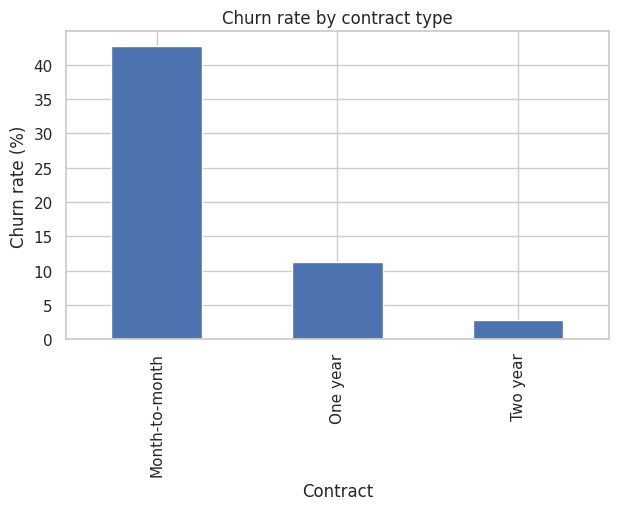

In [5]:
contract_churn = pd.crosstab(df['Contract'], df['Churn'], normalize='index').mul(100)
contract_churn['Yes'].sort_values(ascending=False).plot(kind='bar', figsize=(7, 4), title='Churn rate by contract type')
plt.ylabel('Churn rate (%)')
plt.xlabel('Contract')
plt.show()

## Tenure and monthly charges
Compare distributions to understand overlap between retained and churned customers.

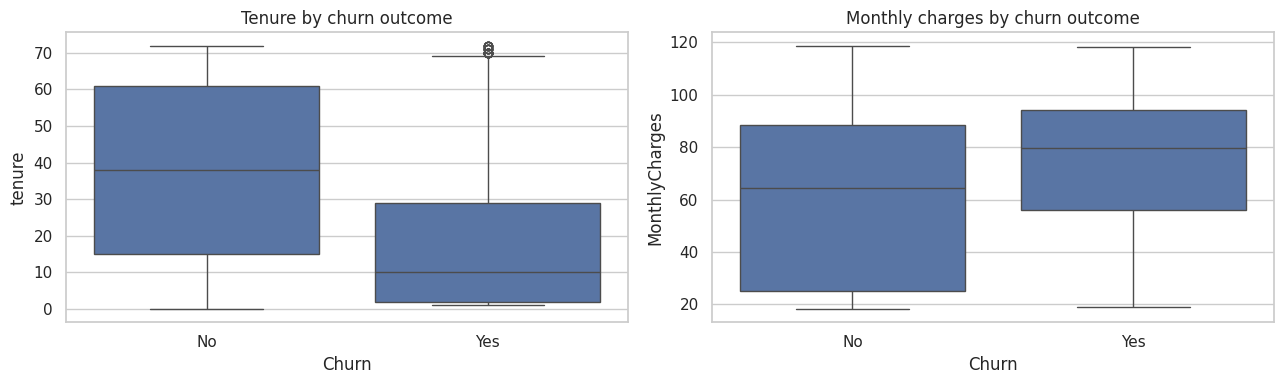

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=df, x='Churn', y='tenure', ax=axes[0])
axes[0].set_title('Tenure by churn outcome')
sns.boxplot(data=df, x='Churn', y='MonthlyCharges', ax=axes[1])
axes[1].set_title('Monthly charges by churn outcome')
plt.tight_layout()

## Initial business observations

Use the charts to identify customer segments with elevated churn. In this dataset, month-to-month contracts and low-tenure customers are usually the first segments to investigate for retention action.

### Interpretation of the original views
Churn accounts for 26.54% of the sample (1,869 of 7,043 customers). Predicting everyone stays would miss every churner despite 73.46% accuracy. Month-to-month customers have a much higher observed churn fraction than customers on longer contracts. Tenure and charges overlap between outcomes, so no single feature perfectly separates the groups.

## Data quality and descriptive statistics
Check the unmodified CSV separately so that conversion does not conceal blank strings. Exact duplicate rows may be removed before splitting; conflicting duplicate customer IDs must instead be investigated. Missing values are imputed inside the training pipeline, never using holdout statistics.

In [7]:
raw = pd.read_csv(ROOT / 'data' / 'WA_Fn-UseC_-Telco-Customer-Churn.csv')
quality = {
    'rows': len(raw), 'columns': len(raw.columns),
    'exact_duplicate_rows': int(raw.duplicated().sum()),
    'duplicate_customer_ids': int(raw['customerID'].duplicated().sum()),
    'blank_total_charges': int(raw['TotalCharges'].astype(str).str.strip().eq('').sum()),
    'missing_total_charges_after_conversion': int(df['TotalCharges'].isna().sum()),
}
display(pd.Series(quality, name='value').to_frame())
display(df.dtypes.rename('dtype').to_frame())
display(df.describe(include='all').T)
missing = df.isna().sum()
display(missing.rename('missing_count').to_frame().assign(missing_pct=missing / len(df) * 100))
assert raw['customerID'].is_unique
assert df['Churn'].isin(['Yes', 'No']).all()


,value
rows,7043
columns,21
exact_duplicate_rows,0
duplicate_customer_ids,0
blank_total_charges,11
missing_total_charges_after_conversion,11


,dtype
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,3186-AJIEK,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,missing_count,missing_pct
customerID,0,0.000000
gender,0,0.000000
SeniorCitizen,0,0.000000
Partner,0,0.000000
Dependents,0,0.000000
tenure,0,0.000000
PhoneService,0,0.000000
MultipleLines,0,0.000000
InternetService,0,0.000000
OnlineSecurity,0,0.000000


### Data-quality interpretation
There are 11 blank total-charge values, no exact duplicate records and no duplicate customer IDs. Blank total charges are missing billing values rather than zero bills. Median imputation preserves these records and is learned only from the training fold. `customerID` is excluded from model features. `SeniorCitizen` is a numeric binary indicator.

## Target distribution with counts
Both counts and percentages matter when planning retention work. A classifier that always predicts “stayed” can achieve high accuracy while identifying no churners.

,customers,percent
Churn,,
No,5174,73.463013
Yes,1869,26.536987


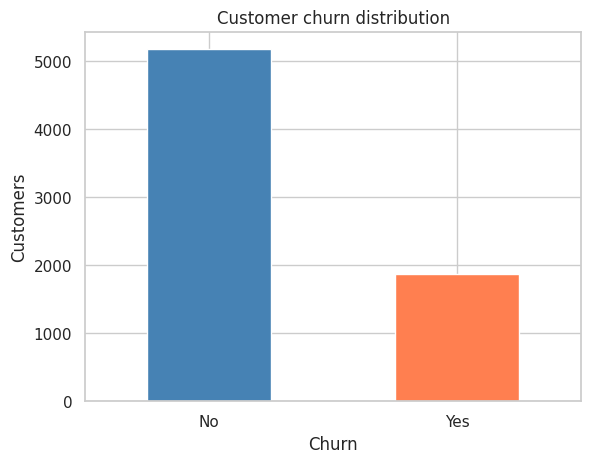

Always predict stayed: accuracy=73.5%, churn recall=0%


In [8]:
counts = df['Churn'].value_counts().reindex(['No', 'Yes'])
display(pd.DataFrame({'customers': counts, 'percent': counts / len(df) * 100}))
counts.plot.bar(rot=0, color=['steelblue', 'coral'], title='Customer churn distribution')
plt.ylabel('Customers')
save_figure('target_distribution.png')
plt.show()
print(f"Always predict stayed: accuracy={counts['No']/len(df):.1%}, churn recall=0%")


## Contract, internet service and payment method
Each rate uses customers within its own group as the denominator. Tables include group sizes so small groups are visible. These are descriptive comparisons without uncertainty intervals or causal claims.

,size,churn_percent
Contract,,
Month-to-month,3875,42.709677
One year,1473,11.269518
Two year,1695,2.831858


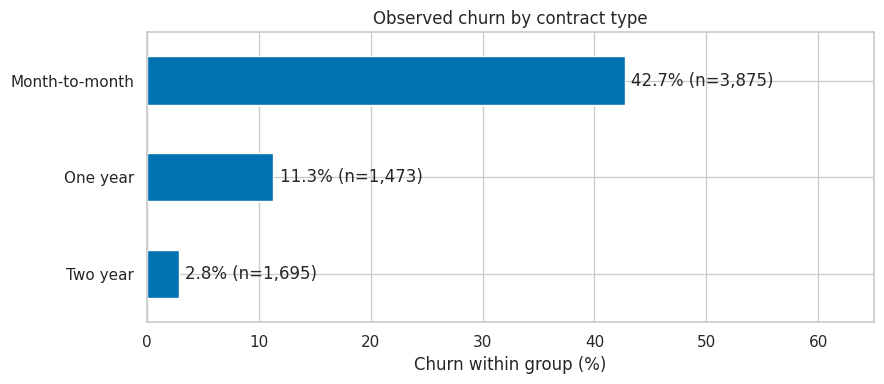

Highest observed rate: Month-to-month (42.7%).


,size,churn_percent
InternetService,,
Fiber optic,3096,41.892765
DSL,2421,18.959108
No,1526,7.404980


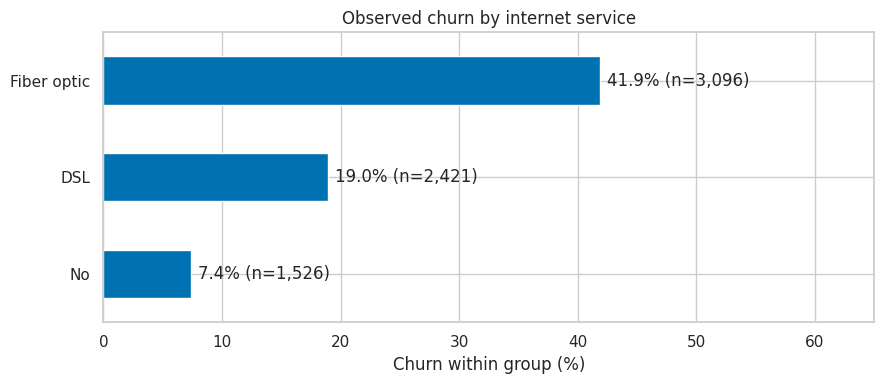

Highest observed rate: Fiber optic (41.9%).


,size,churn_percent
PaymentMethod,,
Electronic check,2365,45.285412
Mailed check,1612,19.106700
Bank transfer (automatic),1544,16.709845
Credit card (automatic),1522,15.243101


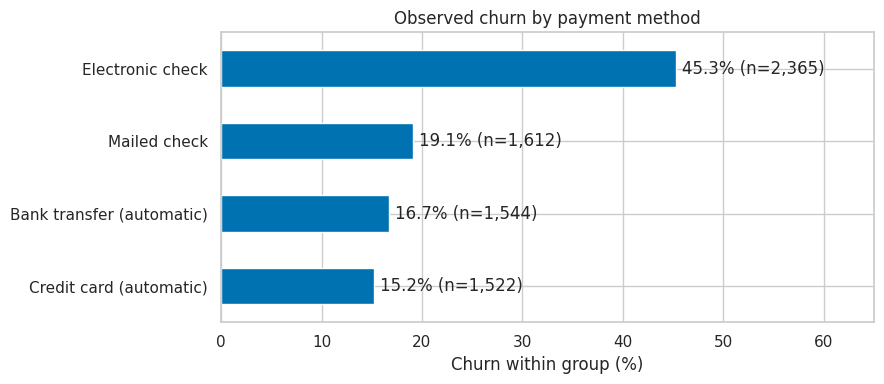

Highest observed rate: Electronic check (45.3%).


In [9]:
labels = {'Contract': 'contract type', 'InternetService': 'internet service',
          'PaymentMethod': 'payment method'}
for column, label in labels.items():
    rates = df.assign(churned=df['Churn'].eq('Yes')).groupby(column)['churned'].agg(['size', 'mean'])
    rates['churn_percent'] = rates.pop('mean') * 100
    rates = rates.sort_values('churn_percent', ascending=False)
    display(rates)
    fig, ax = plt.subplots(figsize=(9, 4))
    rates['churn_percent'].plot.barh(ax=ax, color='#0072B2')
    ax.invert_yaxis()
    for position, row in enumerate(rates.itertuples()):
        ax.text(row.churn_percent + 0.6, position,
                f'{row.churn_percent:.1f}% (n={row.size:,})', va='center')
    ax.set_xlim(0, 65)
    ax.set_xlabel('Churn within group (%)')
    ax.set_ylabel('')
    ax.set_title(f'Observed churn by {label}')
    fig.tight_layout()
    save_figure(f'churn_by_{column.lower()}.png')
    plt.show()
    print(f"Highest observed rate: {rates.index[0]} ({rates.iloc[0]['churn_percent']:.1f}%).")


### Interpretation
Month-to-month churn is 42.71%, versus 11.27% for one-year and 2.83% for two-year contracts. Fiber-optic churn is 41.89%, compared with 18.96% for DSL. Electronic-check customers have 45.29% churn, the highest payment-group rate in this sample. These associations suggest segments for further analysis; they do not show that changing a service or payment method will prevent churn.

## Tenure distribution and monthly charges
Tenure measures months with the company. Inspect counts, median charges and churn proportions together; differences in exposure and subscriptions can confound an apparent price relationship.

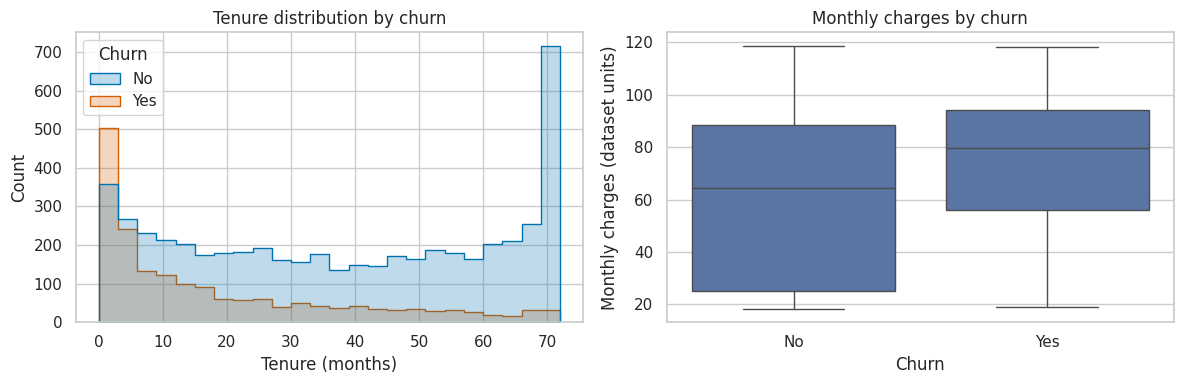

tenure            MonthlyCharges            TotalCharges             
      median       mean         median       mean       median         mean
Churn                                                                      
No      38.0  37.569965         64.425  61.265124      1683.60  2555.344141
Yes     10.0  17.979133         79.650  74.441332       703.55  1531.796094

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=df, x='tenure', hue='Churn', hue_order=['No', 'Yes'], palette=CHURN_COLORS,
             bins=24, element='step', ax=axes[0])
sns.boxplot(data=df, x='Churn', y='MonthlyCharges', ax=axes[1])
axes[0].set_title('Tenure distribution by churn')
axes[0].set_xlabel('Tenure (months)')
axes[1].set_ylabel('Monthly charges (dataset units)')
axes[1].set_title('Monthly charges by churn')
plt.tight_layout()
save_figure('tenure_monthly_charges.png')
plt.show()
display(df.groupby('Churn')[['tenure', 'MonthlyCharges', 'TotalCharges']].agg(['median', 'mean']))


### Interpretation
Churned customers have median tenure of 10 months, versus 38 months for retained customers. Median monthly charges are 79.65 versus 64.43, respectively. Short-tenure onboarding and higher-charge segments merit investigation, but charge distributions overlap and contract/service mix can confound the relationship.

## Relationships between features and churn
Tenure bands show how the churn fraction varies over the customer lifecycle. Numeric correlations include the binary target for descriptive purposes; they do not capture all categorical or nonlinear effects. `customerID` is never included.

,customers,churn_fraction
tenure_band,,
0–12,2186,0.474382
13–24,1024,0.287109
25–48,1594,0.203890
49–72,2239,0.095132


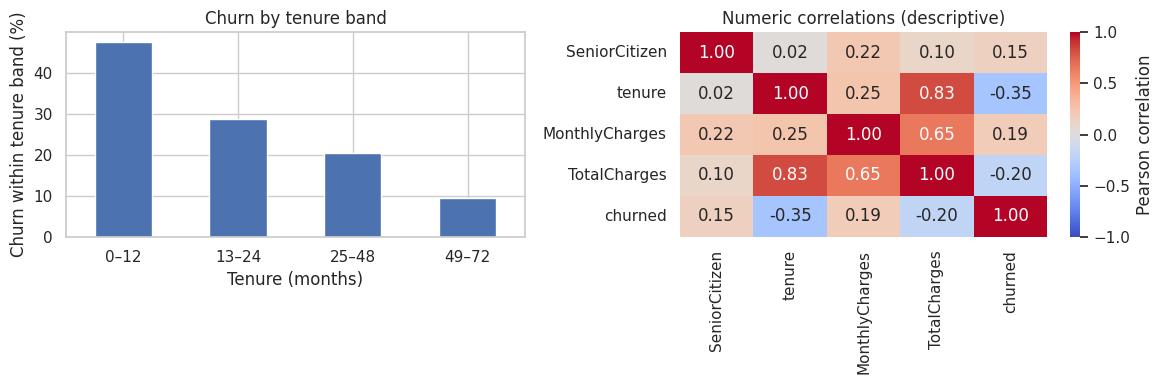

In [11]:
analysis = df.assign(churned=df['Churn'].eq('Yes').astype(int))
analysis['tenure_band'] = pd.cut(analysis['tenure'], [-1, 12, 24, 48, 72], labels=['0–12', '13–24', '25–48', '49–72'])
tenure_rates = analysis.groupby('tenure_band', observed=True)['churned'].agg(['size', 'mean'])
display(tenure_rates.rename(columns={'size': 'customers', 'mean': 'churn_fraction'}))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
(tenure_rates['mean'] * 100).plot.bar(ax=axes[0], rot=0, title='Churn by tenure band')
axes[0].set_ylabel('Churn within tenure band (%)')
axes[0].set_xlabel('Tenure (months)')
sns.heatmap(analysis[['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'churned']].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1,
            cbar_kws={'label': 'Pearson correlation'}, ax=axes[1])
axes[1].set_title('Numeric correlations (descriptive)')
plt.tight_layout()
save_figure('feature_relationships.png')
plt.show()


## Modeling handoff and limitations

- Keep the raw dataset unchanged; blank charges and missing features are handled in the saved pipeline.
- Use a stratified 80/20 split with seed 42. Fit imputation, scaling and encoding only on training folds.
- Compare Logistic Regression and Random Forest using three-fold training-only cross-validation ROC-AUC. Select before inspecting holdout scores.
- Report precision, recall, F1, ROC-AUC, accuracy, confusion matrices and classification reports. Accuracy alone ignores missed churners in the minority class.
- Class weighting addresses imbalance but can distort probability calibration. Low/Medium/High risk bands are illustrative; validate calibration, intervention costs and thresholds before deployment.
- EDA uses the full sample to describe it. This is a portfolio benchmark, not a blinded external study; future work needs a new temporal or external holdout.
- The data is fictional, cross-sectional and contains no timestamps or intervention outcomes. Correlation is not causation.

Run `python src/train.py` from the repository root to generate real evaluation results. The README and `reports/model_metrics.json` record the executed experiment.